In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

In [198]:
def OS_model(t, *args):
    T_0,T_peak,T_os,t_up,t_plat,t_down=args
    out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up
    out = np.concatenate([out,[T_peak]*len(t[(t_up<t)&(t<=t_up+t_plat)])])
    out = np.concatenate([out, T_peak - (t[(t_up+t_plat<t)&(t<=t_down+t_up+t_plat)]-t_up-t_plat)*(T_peak-T_os)/(t_down)])
    return np.concatenate([out, [T_os]*(len(t)-len(out))])

def OS_model_alt(t, *args):
    T_0,T_peak,T_os,r_up,t_plat,r_down=args
    t_up = (T_peak-T_0)/r_up
    t_down = (T_peak-T_os)/r_down
    out = T_0 + t[t<=t_up]*r_up
    out = np.concatenate([out,
                          [T_peak]*len(t[(t_up<t)&(t<=t_up+t_plat)])])
    out = np.concatenate([out, 
                          T_peak - (t[(t_up+t_plat<t)&(t<=t_down+t_up+t_plat)]
                                    -t_up-t_plat)*r_down])
    return np.concatenate([out, [T_os]*(len(t)-len(out))])

def OS_model_red(t,*args,T_0=1.1452,t_plat=20):
    T_peak,T_os,t_up,t_down=args
    return OS_model(t,T_0,T_peak,T_os,t_up,t_plat,t_down)


def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=10):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

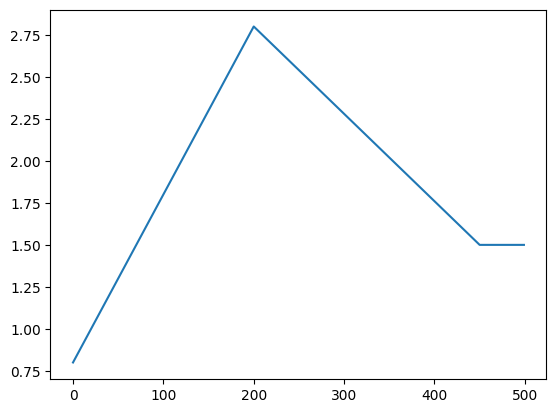

In [41]:
plt.plot(x,OS_model(x,T_0,T_peak,T_os,t_up,t_down))

In [12]:
t_up=100
t_down=200
t=np.arange(50,300,step=25)
print((t_up<t)&(t<=t_down))

[False False False  True  True  True  True False False False]


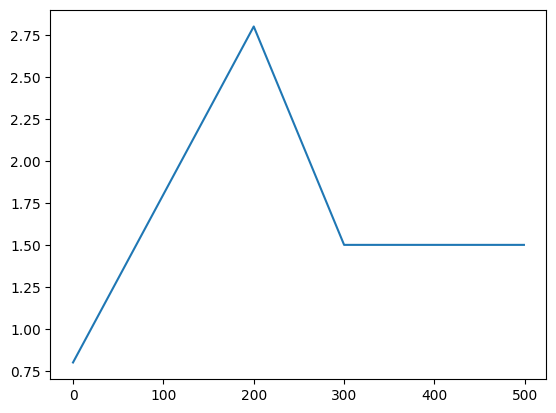

In [10]:
years = np.arange(500)
temp = np.array([OS_model(y,0.8,2.8,1.5,200,100) for y in years])
plt.plot(years,temp)

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

In [3]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [46]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

## 6-parameter model

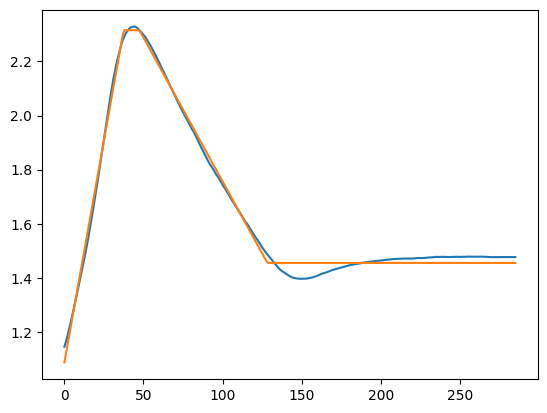

In [180]:
temp = df['ssp534-over'].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, T_ref, (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, T_ref-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, T_max+0.5, len(ydata), 100, len(ydata)]) )
                       # bounds=[(T_ref-0.5,T_ref+0.5), 
                       #         (T_max-0.5,T_max+0.5),
                       #         (T_ref-0.5,T_max+0.5), 
                       #         (10,500), 
                       #         (10,500)])
plt.plot(xdata,ydata)
plt.plot(xdata,OS_model(xdata,*popt))

In [220]:
# T0_std = np.zeros(16)
# for i,t_ref in enumerate(np.arange(2000,2016)):
t_ref=2015
xdata = np.arange(t_ref,2301)-t_ref
popt={}
pcov={}

popt_alt = {}
pcov_alt={}
for s in scenarios:
    ydata=df[s].to_numpy()[t_ref-1850:]
    popt[s], pcov[s] = curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], (ydata.max()-ydata[0])/0.01, 10 ,(ydata.max()-T_ref)/0.01],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata.max()+0.5, len(ydata), 50, len(ydata)]) )
    popt_alt[s], pcov_alt[s] = curve_fit(OS_model_alt, xdata, ydata,
                                         p0=[ydata[0], ydata.max(), ydata[-1], 0.02, 10 ,0.02],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata.max()+0.5, 0.04, 50, 0.05]) )


In [221]:
perr_n = np.array([np.sqrt(np.diag(pcov[s]))/popt[s] for s in scenarios])
perr_alt_n = np.array([np.sqrt(np.diag(pcov_alt[s]))/popt_alt[s] for s in scenarios])
print(perr_n[0,:])

[2.99322262e-03 7.51123602e-04 6.98181315e-04 2.21158571e-03
 0.00000000e+00 2.69930847e+05]


In [224]:
popt_alt[scenarios[1]]

array([1.10009253, 3.30206667, 1.50422   , 0.02132007, 3.44044134,
       0.01098071])

Text(0, 0.5, 'Initial temp. (°C)')

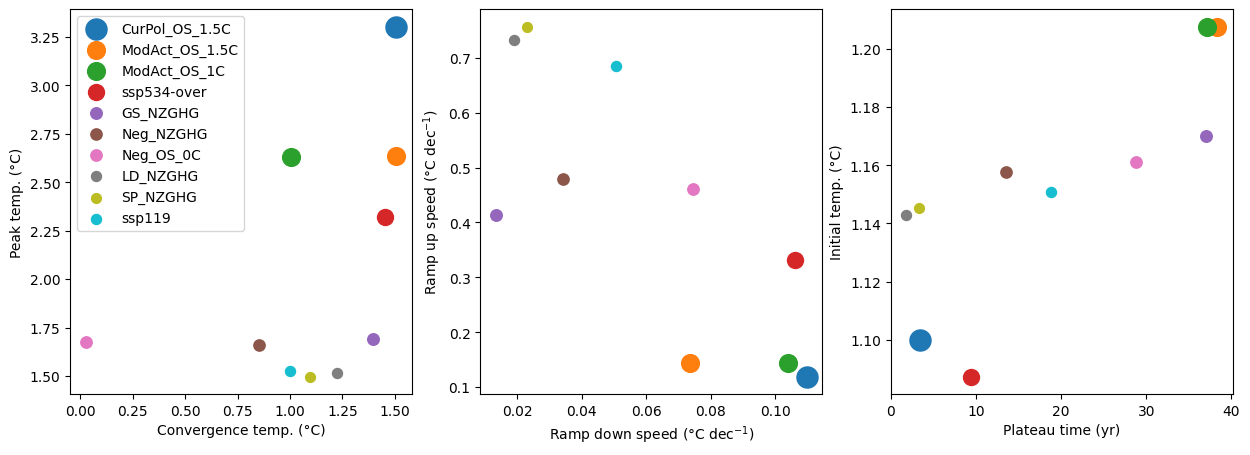

In [228]:
fig,axs=plt.subplots(figsize=(15,5), ncols=3)
plotted_scen = []
for s in scenarios:
    T_0,T_peak,T_os,t_up,t_plat,t_down=popt[s]
    if (T_peak-T_os)/t_down>0: #t_down>25:
        axs[0].scatter(T_os,T_peak,label=s,s=100*(T_peak-1.5)+50)
        # axs[1].scatter(t_down,t_up)
        axs[1].scatter(10*(T_peak-T_os)/t_down,10*(T_max-T_0)/t_up,s=100*(T_peak-1.5)+50)
        axs[2].scatter(t_plat,T_0,s=100*(T_peak-1.5)+50)
        plotted_scen += [s]
axs[0].set_xlabel('Convergence temp. (°C)')
axs[0].set_ylabel('Peak temp. (°C)')
axs[0].legend()

# axs[1].set_xlabel('Ramp down time (yr)')
# axs[1].set_ylabel('Ramp up time (yr)')
axs[1].set_xlabel('Ramp down speed (°C dec$^{-1}$)')
axs[1].set_ylabel('Ramp up speed (°C dec$^{-1}$)')

axs[2].set_xlabel('Plateau time (yr)')
axs[2].set_ylabel('Initial temp. (°C)')
# fig.savefig('../../Figures/Overshoots/PROVIDE/fitted_parameters.png',bbox_inches='tight')

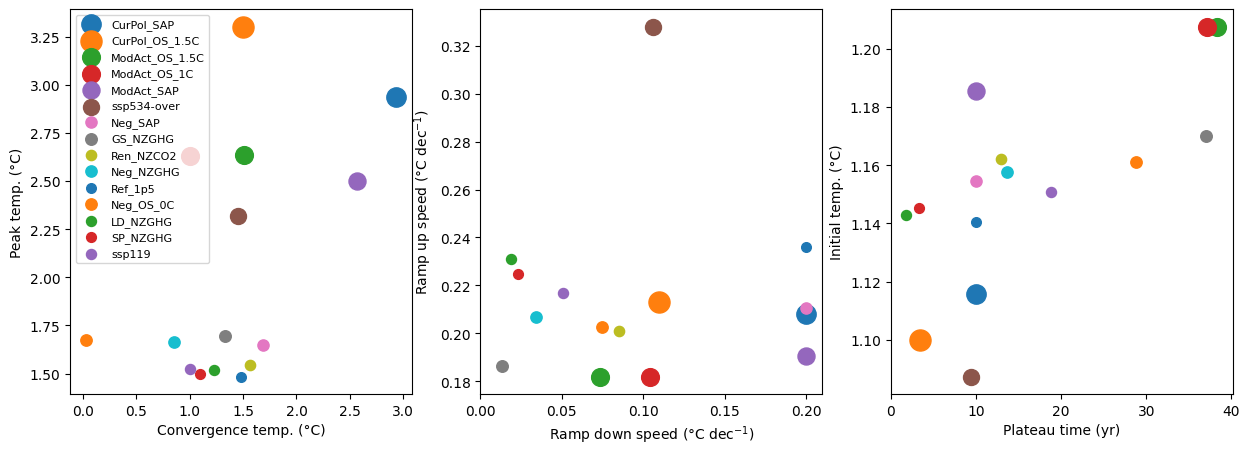

In [245]:
fig,axs=plt.subplots(figsize=(15,5), ncols=3)
for s in scenarios:#plotted_scen:#scenarios:
    T_0,T_peak,T_os,r_up,t_plat,r_down=popt_alt[s]
    axs[0].scatter(T_os,T_peak,label=s,s=100*(T_peak-1.5)+50)
    # axs[1].scatter(t_down,t_up)
    axs[1].scatter(10*r_down,10*r_up,s=100*(T_peak-1.5)+50)
    axs[2].scatter(t_plat,T_0,s=100*(T_peak-1.5)+50)
axs[0].set_xlabel('Convergence temp. (°C)')
axs[0].set_ylabel('Peak temp. (°C)')
axs[0].legend(fontsize=8)

# axs[1].set_xlabel('Ramp down time (yr)')
# axs[1].set_ylabel('Ramp up time (yr)')
axs[1].set_xlabel('Ramp down speed (°C dec$^{-1}$)')
axs[1].set_ylabel('Ramp up speed (°C dec$^{-1}$)')
axs[1].set_xlim(0,0.21)

axs[2].set_xlabel('Plateau time (yr)')
axs[2].set_ylabel('Initial temp. (°C)')
fig.savefig('../../Figures/Overshoots/PROVIDE/fitted_parameters_alt.png',bbox_inches='tight')

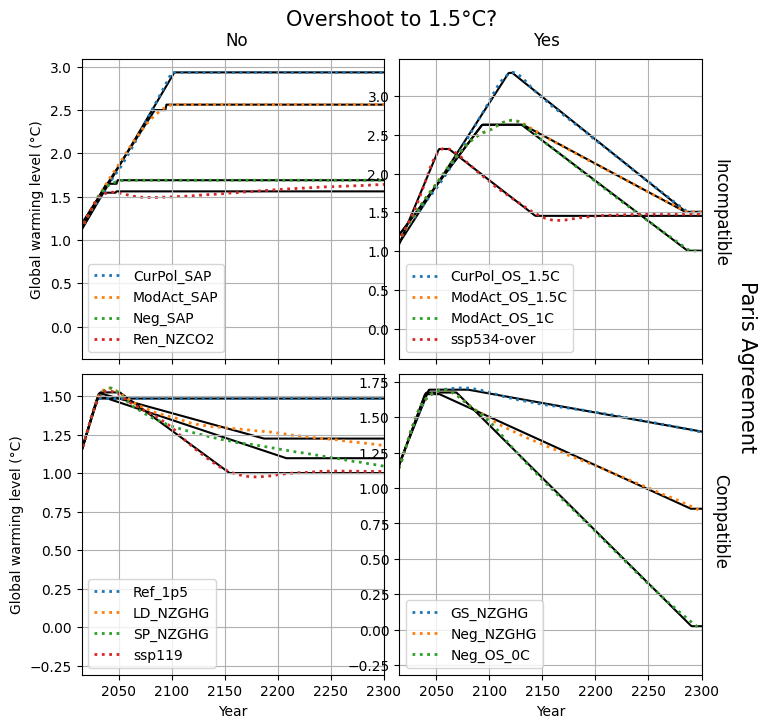

In [241]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=False)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
# t_ref=2015
xdata = np.arange(t_ref,2301)-t_ref
axs[0,0].set_xlim(t_ref,2300)
# axs[0,0].set_ylim(0,3.5)
# axs[0,0].set_ylim(-0.01,0.01)
n=0 # nth derivative
N=1 # window for moving_avg
for s in scenarios:
    temp=df[s].to_numpy()
    # T_0,T_peak,T_os,t_up,t_plat,t_down=popt[s]
    # if (T_peak-T_os)/t_down>0:
    axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850+n,2301), 
                                                                             moving_avg(np.diff(temp,n=n),N=1), label=s,ls=':',zorder=1,lw=2)
for s in scenarios:
    temp=df[s].to_numpy()
    T_0,T_peak,T_os,r_up,t_plat,r_down=popt_alt[s]
    # if (T_peak-T_os)/t_down>0:
    axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(t_ref,2301), 
                                                                             OS_model_alt(xdata,*popt_alt[s]), color='k',ls='-',zorder=0)

for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend()
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Global warming level (°C)')

# axs[1,0].tick_params(axis='x',labelrotation=+45)

# axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,0].tick_params(axis='x',pad=12)
# axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
# fig.tight_layout()
# axs[1,0].set_xticks([2000,2050,2100,2150,2200,2250])

# fig.savefig('../../Figures/Overshoots/PROVIDE/temperatures_to_2300.png',bbox_inches='tight')

In [203]:
for s in scenarios:
    T_0,T_peak,T_os,r_up,t_plat,r_down=popt_alt[s]
    # if (T_peak-T_os)/t_down>0:
    print(s, r_down*10, '°C/dec')
        # print(s,t_plat, 'yr')

CurPol_SAP 0.2 °C/dec
CurPol_OS_1.5C 0.10980710479558563 °C/dec
ModAct_OS_1.5C 0.07353973839059584 °C/dec
ModAct_OS_1C 0.10401717056231094 °C/dec
ModAct_SAP 0.2 °C/dec
ssp534-over 0.10609848623721724 °C/dec
Neg_SAP 0.2 °C/dec
GS_NZGHG 0.013428066138197893 °C/dec
Ren_NZCO2 0.06115724275300238 °C/dec
Neg_NZGHG 0.0341083014916026 °C/dec
Ref_1p5 0.2 °C/dec
Neg_OS_0C 0.07442711707078421 °C/dec
LD_NZGHG 0.01903698374919071 °C/dec
SP_NZGHG 0.023040423195718685 °C/dec
ssp119 0.0506179326175819 °C/dec


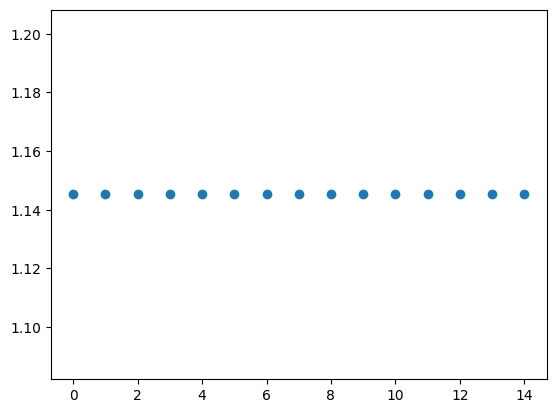

In [150]:
plt.scatter(range(len(scenarios)), [df[s].to_numpy()[t_ref-1850] for s in scenarios])

In [157]:
print(np.mean([popt[s][-2] 
               for s in scenarios 
               if (popt[s][1]-popt[s][2])/popt[s][-1]>0]))

19.250540186352396


In [59]:
print((popt[1]-popt[0])/popt[3])

0.03283073438993622


In [22]:
len(temp[2015-1850:])

286

## 4-parameter reduced model

In [179]:
# T0_std = np.zeros(16)
# for i,t_ref in enumerate(np.arange(2000,2016)):
def OS_model_red(t,*args,T_0=1.1452,t_plat=0):
    T_peak,T_os,t_up,t_down=args
    return OS_model(t,T_0,T_peak,T_os,t_up,t_plat,t_down)
t_ref=2015
xdata = np.arange(t_ref,2301)-t_ref
popt={}
pcov={}
for s in scenarios:
    ydata=df[s].to_numpy()[t_ref-1850:]
    popt[s], pcov[s] = curve_fit(OS_model_red, xdata, ydata,
                                 p0=[ydata.max(), ydata[-1], (ydata.max()-ydata[0])/0.01, (ydata.max()-T_ref)/0.01],
                                 bounds = ([ydata.max()-0.5, ydata[-1]-0.5, 0, 0],
                                 [ydata.max()+0.5, ydata.max()+0.5, len(ydata), len(ydata)]))
    T_peak,T_os,t_up,t_down=popt[s]
    # if (T_peak-T_os)/t_down>0:
    #     print(s, T_0, '°C')
    # T0_std[i]=np.std([popt[s][0] for s in scenarios])

Text(0, 0.5, 'Ramp up speed (°C dec$^{-1}$)')

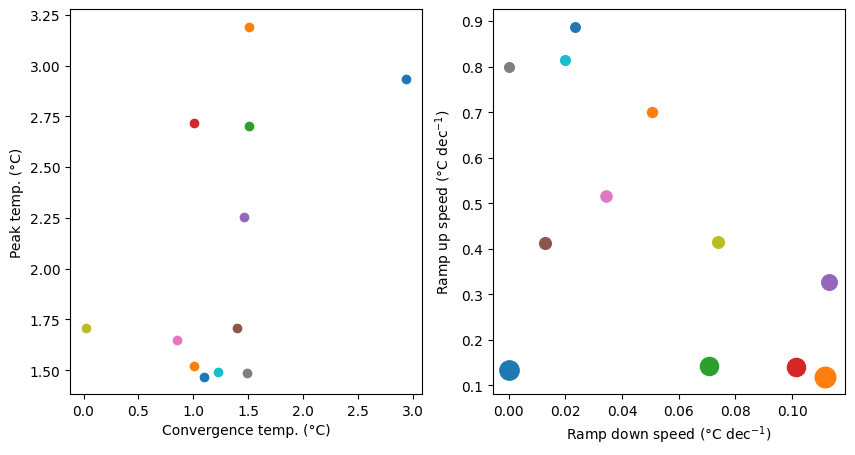

In [167]:
fig,axs=plt.subplots(figsize=(10,5), ncols=2)
for s in scenarios:
    T_peak,T_os,t_up,t_down=popt[s]
    if (T_peak-T_os)/t_down>0: #t_down>25:
        axs[0].scatter(T_os,T_peak,label=s)
        axs[1].scatter(10*(T_peak-T_os)/t_down,10*(T_max-T_0)/t_up,s=100*(T_peak-1.5)+50)
        # axs[2].scatter(t_plat,T_0)
axs[0].set_xlabel('Convergence temp. (°C)')
axs[0].set_ylabel('Peak temp. (°C)')
# axs[0].legend()

axs[1].set_xlabel('Ramp down speed (°C dec$^{-1}$)')
axs[1].set_ylabel('Ramp up speed (°C dec$^{-1}$)')

ValueError: too many values to unpack (expected 4)

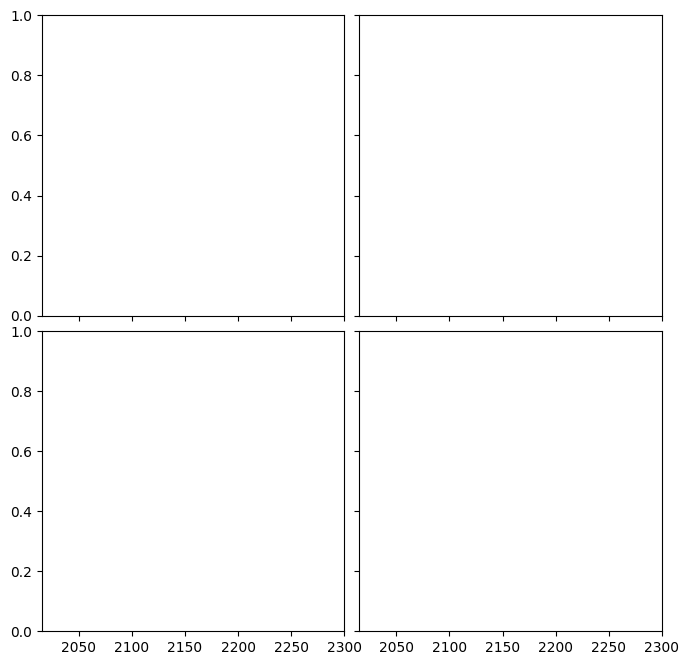

In [176]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
# t_ref=2015
xdata = np.arange(t_ref,2301)-t_ref
axs[0,0].set_xlim(t_ref,2300)
# axs[0,0].set_ylim(0,3.5)
# axs[0,0].set_ylim(-0.01,0.01)
n=0 # nth derivative
N=1 # window for moving_avg
for s in scenarios:
    temp=df[s].to_numpy()
    T_peak,T_os,t_up,t_down=popt[s]
    if (T_peak-T_os)/t_down>0:
    # axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), temp, label=s)
        axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].scatter(np.arange(1850+n,2301), 
                                                                             moving_avg(np.diff(temp,n=n),N=1), label=s,marker='x',s=5)
for s in scenarios:
    temp=df[s].to_numpy()
    T_peak,T_os,t_up,t_down=popt[s]
    if (T_peak-T_os)/t_down>0:
        axs[int(PA_compliant(moving_avg(temp))), int(OS_ref(temp,ref=1.5))].plot(np.arange(t_ref,2301), 
                                                                             OS_model_red(xdata,*popt[s]), color='k')

for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend()
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Global warming level (°C)')

# axs[1,0].tick_params(axis='x',labelrotation=+45)

# axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,0].tick_params(axis='x',pad=12)
# axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
# fig.tight_layout()
# axs[1,0].set_xticks([2000,2050,2100,2150,2200,2250])

# fig.savefig('../../Figures/Overshoots/PROVIDE/temperatures_to_2300.png',bbox_inches='tight')